<a href="https://colab.research.google.com/github/animeshsahoo5/AI-Powered-Customer-Support-Chatbot/blob/main/AI_Chatbot_Capstone_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Capstone Project – AI-Powered Intelligent Chatbot**

### Project objectives
- Build a domain-specific AI chatbot.
- Compare a traditional NLP baseline with a Transformer-based approach.
- Evaluate intent classification performance.
- Generate visualizations for the technical report.
- Provide a simple interactive chatbot interface inside Colab.
- Document methodology, design decisions, results, and limitations.

### Approach
**Baseline:** TF-IDF + Logistic Regression  
**Proposed:** Sentence-Transformer embeddings + cosine similarity  
**Interface:** Gradio

## 1. Workflow

```text
User Query
    ↓
Text Preprocessing
    ↓
┌───────────────────────────────┐
│ Baseline: TF-IDF + Logistic   │
│ Proposed: Transformer Encoder │
└───────────────────────────────┘
    ↓
Intent Detection
    ↓
Response Selection
    ↓
Chatbot Response
```

In [38]:
# Install required packages
!pip -q install sentence-transformers gradio scikit-learn pandas matplotlib seaborn

In [39]:
import re
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix
)
from sentence_transformers import SentenceTransformer
import gradio as gr

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

print("Env. ready.")

Env. ready.


## 2. Dataset

The sample dataset containg common customer-support intents:
- greeting
- goodbye
- office_hours
- location
- services
- pricing
- contact
- support
- refund
- thanks

In [40]:
intents = {
    "greeting": {
        "patterns": [
            "hello", "hi", "hey", "good morning", "good afternoon",
            "good evening", "is anyone there", "hi there"
        ],
        "responses": [
            "Hello! How can I help you today?",
            "Hi! What can I do for you?"
        ]
    },
    "goodbye": {
        "patterns": [
            "bye", "goodbye", "see you", "talk to you later",
            "have a nice day", "i am leaving"
        ],
        "responses": [
            "Goodbye! Have a great day.",
            "Thanks for chatting. See you again!"
        ]
    },
    "office_hours": {
        "patterns": [
            "what are your office hours", "when is the office open",
            "what time do you open", "what time do you close",
            "when can i visit the office", "are you open today",
            "what are your working hours"
        ],
        "responses": [
            "Our office is open from 9 AM to 6 PM, Monday to Friday."
        ]
    },
    "location": {
        "patterns": [
            "where is your office", "what is your location",
            "where are you located", "give me your address",
            "how can i find your office", "where is the company located"
        ],
        "responses": [
            "Our office is located in Bhubaneswar."
        ]
    },
    "services": {
        "patterns": [
            "what services do you provide", "what do you offer",
            "tell me about your services", "which services are available",
            "what can your company do", "what products do you provide"
        ],
        "responses": [
            "We provide software development, cloud, AI, and digital services."
        ]
    },
    "pricing": {
        "patterns": [
            "how much does it cost", "what is the price",
            "tell me your pricing", "how much do your services cost",
            "what are your charges", "do you have a pricing plan"
        ],
        "responses": [
            "Our pricing depends on the service and project requirements."
        ]
    },
    "contact": {
        "patterns": [
            "how can i contact you", "what is your contact number",
            "how do i reach support", "give me your email",
            "who should i contact", "how can i get in touch"
        ],
        "responses": [
            "You can contact our support team through the official company email(sahooanimesh555@gmail.com) or phone number(xxxxxxxxxx)."
        ]
    },
    "support": {
        "patterns": [
            "i need help", "i have a problem", "something is not working",
            "can you help me", "i need technical support",
            "help me with an issue", "there is an error"
        ],
        "responses": [
            "Sure. Please describe the issue and I will help you troubleshoot it."
        ]
    },
    "refund": {
        "patterns": [
            "i want a refund", "how can i get my money back",
            "what is the refund policy", "can i get a refund",
            "i need to cancel and get a refund", "refund request"
        ],
        "responses": [
            "Please contact support(755897288) with your order details to start a refund request."
        ]
    },
    "thanks": {
        "patterns": [
            "thank you", "thanks", "thanks a lot", "that was helpful",
            "i appreciate your help", "many thanks"
        ],
        "responses": [
            "You're welcome!",
            "Happy to help!"
        ]
    }
}

rows = []
for intent, item in intents.items():
    for pattern in item["patterns"]:
        rows.append({"text": pattern, "intent": intent})

df = pd.DataFrame(rows)
display(df.head(10))
print("\nIntent distribution:")
display(df["intent"].value_counts().sort_index())

,text,intent
0,hello,greeting
1,hi,greeting
2,hey,greeting
3,good morning,greeting
4,good afternoon,greeting
5,good evening,greeting
6,is anyone there,greeting
7,hi there,greeting
8,bye,goodbye
9,goodbye,goodbye



Intent distribution:


,count
intent,
contact,6
goodbye,6
greeting,8
location,6
office_hours,7
pricing,6
refund,6
services,6
support,7


## 3. Text Preprocessing


In [41]:
def preprocess_text(text: str) -> str:
    text = str(text).lower()
    text = re.sub(r"\s+", " ", text)
    return text.strip()

print( "null value:\n",df.isnull().sum())
print("duplicate value:",df.duplicated().sum())
df["clean_text"] = df["text"].apply(preprocess_text)
df.head()



null value:
 text      0
intent    0
dtype: int64
duplicate value: 0


,text,intent,clean_text
0,hello,greeting,hello
1,hi,greeting,hi
2,hey,greeting,hey
3,good morning,greeting,good morning
4,good afternoon,greeting,good afternoon


## 4. Train/Test Split



In [42]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean_text"],
    df["intent"],
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=df["intent"]
)

## 5. Intent-Model

TF-IDF converts text into numeric features. Logistic Regression then predicts the most likely intent.


In [43]:
tfidf = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

intent_model = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE
)

intent_model.fit(X_train_tfidf, y_train)

intent_pred = intent_model.predict(X_test_tfidf)

intent_acc = accuracy_score(y_test, intent_pred)
intent_precision, intent_recall, intent_f1, _ = precision_recall_fscore_support(
    y_test, intent_pred, average="weighted", zero_division=0
)

print("Accuracy :", intent_acc)
print("Precision:", intent_precision)
print("Recall   :" ,intent_recall)
print("F1-score :", intent_f1)

Accuracy : 0.5625
Precision: 0.5729166666666666
Recall   : 0.5625
F1-score : 0.5208333333333333


## 6. Proposed Model — Sentence Transformer

The Transformer model converts each utterance into a semantic embedding.  
A new user query is compared with training examples using cosine similarity.


In [44]:
transformer_model = SentenceTransformer("all-MiniLM-L6-v2")

train_embeddings = transformer_model.encode(
    X_train.tolist(),
    normalize_embeddings=True,
    show_progress_bar=True
)

test_embeddings = transformer_model.encode(
    X_test.tolist(),
    normalize_embeddings=True,
    show_progress_bar=True
)

# Build a label-aligned reference matrix.
train_labels = y_train.to_numpy()

transformer_predictions = []
transformer_latencies_ms = []

for emb in test_embeddings:
    start = time.perf_counter()
    similarities = np.dot(train_embeddings, emb)
    best_idx = int(np.argmax(similarities))
    transformer_predictions.append(train_labels[best_idx])
    transformer_latencies_ms.append((time.perf_counter() - start) * 1000)

acc = accuracy_score(y_test, transformer_predictions)
precision, recall, f1, _ = precision_recall_fscore_support(
    y_test, transformer_predictions, average="weighted", zero_division=0
)

print(f"Transformer Accuracy : {acc:.4f}")
print(f"Transformer Precision: {precision:.4f}")
print(f"Transformer Recall   : {recall:.4f}")
print(f"Transformer F1-score : {f1:.4f}")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/2 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Transformer Accuracy : 1.0000
Transformer Precision: 1.0000
Transformer Recall   : 1.0000
Transformer F1-score : 1.0000


## 7. Model Comparison


In [45]:
results = pd.DataFrame({
    "Model": ["TF-IDF + Logistic Regression", "Sentence Transformer"],
    "Accuracy": [intent_acc, acc],
    "Precision": [intent_precision, precision],
    "Recall": [intent_recall, recall],
    "F1": [intent_f1, f1]
})

display(results.round(4))

,Model,Accuracy,Precision,Recall,F1
0,TF-IDF + Logistic Regression,0.5625,0.5729,0.5625,0.5208
1,Sentence Transformer,1.0000,1.0000,1.0000,1.0000


## 8. Visualization 1 — Intent Distribution

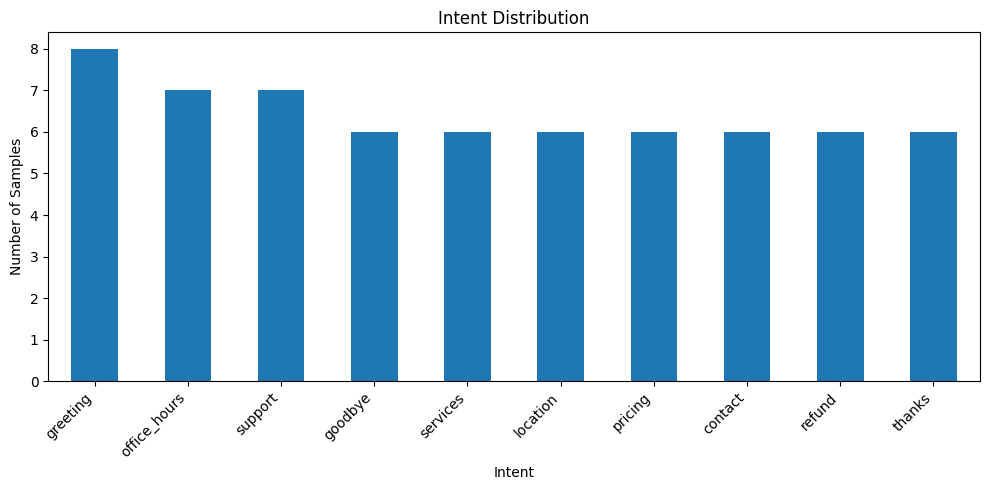

In [46]:
plt.figure(figsize=(10, 5))
df["intent"].value_counts().sort_values(ascending=False).plot(kind="bar")
plt.title("Intent Distribution")
plt.xlabel("Intent")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 9. Visualization 2 — Model Performance Comparison

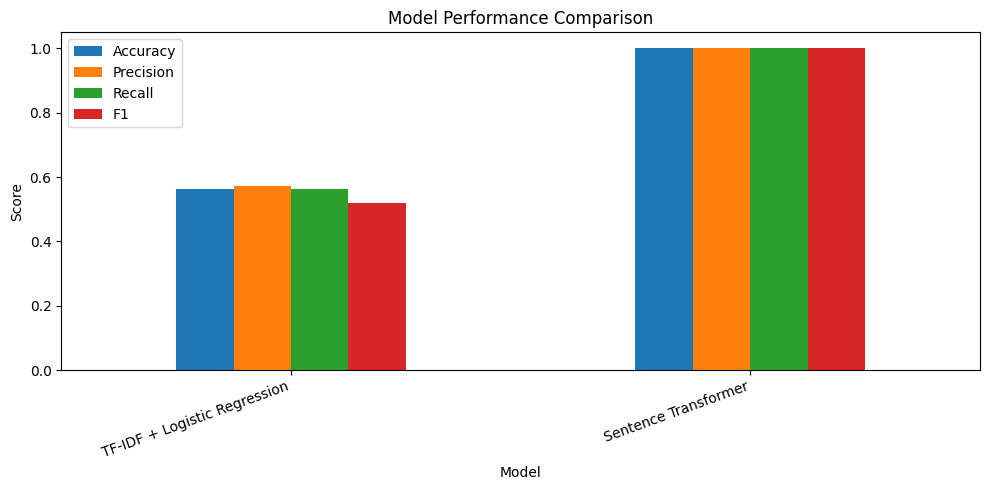

In [47]:
plot_df = results.set_index("Model")[["Accuracy", "Precision", "Recall", "F1"]]

ax = plot_df.plot(kind="bar", figsize=(10, 5))
ax.set_title("Model Performance Comparison")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## 10. Visualization 3 — Confusion Matrix

A confusion matrix shows which intents the model confuses with each other.

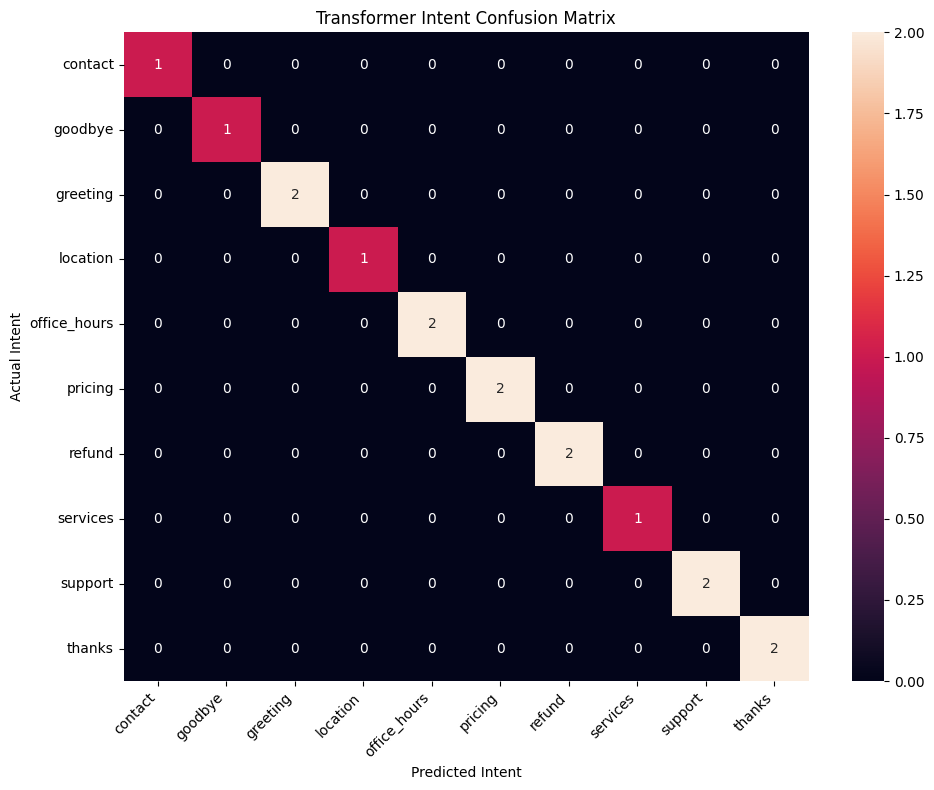

In [48]:
labels = sorted(df["intent"].unique())

cm = confusion_matrix(y_test, transformer_predictions, labels=labels)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", xticklabels=labels, yticklabels=labels)
plt.title("Transformer Intent Confusion Matrix")
plt.xlabel("Predicted Intent")
plt.ylabel("Actual Intent")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 11. Visualization 4 — Response/Prediction Latency

Latency is measured during semantic matching. Encoding a query with the Transformer is separate from the nearest-neighbour lookup, so this chart reflects the matching stage only.

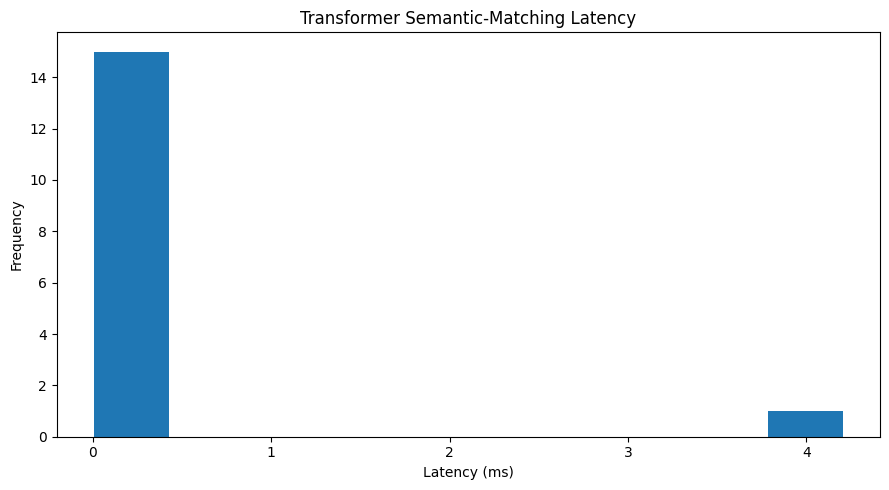

Average matching latency: 0.274 ms


In [49]:
latency_df = pd.DataFrame({"latency_ms": transformer_latencies_ms})

plt.figure(figsize=(9, 5))
plt.hist(latency_df["latency_ms"], bins=10)
plt.title("Transformer Semantic-Matching Latency")
plt.xlabel("Latency (ms)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

print(f"Average matching latency: {latency_df['latency_ms'].mean():.3f} ms")

## 12. Per-Intent Classification Report

In [50]:
print(classification_report(
    y_test,
    transformer_predictions,
    labels=labels,
    zero_division=0
))

              precision    recall  f1-score   support

     contact       1.00      1.00      1.00         1
     goodbye       1.00      1.00      1.00         1
    greeting       1.00      1.00      1.00         2
    location       1.00      1.00      1.00         1
office_hours       1.00      1.00      1.00         2
     pricing       1.00      1.00      1.00         2
      refund       1.00      1.00      1.00         2
    services       1.00      1.00      1.00         1
     support       1.00      1.00      1.00         2
      thanks       1.00      1.00      1.00         2

    accuracy                           1.00        16
   macro avg       1.00      1.00      1.00        16
weighted avg       1.00      1.00      1.00        16



## 13. Chatbot Response Engine

The response engine uses the predicted intent and returns a suitable response.  
A confidence threshold is added so uncertain questions can be safely rejected instead of receiving a random answer.

In [51]:
all_texts = df["clean_text"].tolist()
all_labels = df["intent"].to_numpy()

all_embeddings = transformer_model.encode(
    all_texts,
    normalize_embeddings=True,
    show_progress_bar=True
)

CONFIDENCE_THRESHOLD = 0.45

def predict_intent_transformer(message: str):
    clean = preprocess_text(message)
    query_embedding = transformer_model.encode(
        [clean],
        normalize_embeddings=True
    )[0]

    similarities = np.dot(all_embeddings, query_embedding)
    best_idx = int(np.argmax(similarities))

    return all_labels[best_idx], float(similarities[best_idx])

def chatbot_response(message: str) -> str:
    if not message or not message.strip():
        return "Please enter a question."

    intent, confidence = predict_intent_transformer(message)

    if confidence < CONFIDENCE_THRESHOLD:
        return (
            "I'm not confident that I understand the question. "
            "Please rephrase it or contact support."
        )

    return random.choice(intents[intent]["responses"])

test_questions = [
    "What time do you open?",
    "Where are you located?",
    "I need help with an issue.",
    "Can I get my money back?",
    "Thank you for helping me.",
    "Hello"
]

for q in test_questions:
    intent, confidence = predict_intent_transformer(q)
    print(f"User     : {q}")
    print(f"Intent   : {intent}")
    print(f"Confidence: {confidence:.3f}")
    print(f"Bot      : {chatbot_response(q)}")
    print("-" * 60)

Batches:   0%|          | 0/2 [00:00<?, ?it/s]

User     : What time do you open?
Intent   : office_hours
Confidence: 0.975
Bot      : Our office is open from 9 AM to 6 PM, Monday to Friday.
------------------------------------------------------------
User     : Where are you located?
Intent   : location
Confidence: 0.874
Bot      : Our office is located in Bhubaneswar.
------------------------------------------------------------
User     : I need help with an issue.
Intent   : support
Confidence: 0.788
Bot      : Sure. Please describe the issue and I will help you troubleshoot it.
------------------------------------------------------------
User     : Can I get my money back?
Intent   : refund
Confidence: 0.907
Bot      : Please contact support(755897288) with your order details to start a refund request.
------------------------------------------------------------
User     : Thank you for helping me.
Intent   : thanks
Confidence: 0.591
Bot      : You're welcome!
------------------------------------------------------------
User    

## 14. Interactive Chatbot

Gradio provides a simple browser interface .

In [52]:
demo = gr.Interface(
    fn=chatbot_response,
    inputs=gr.Textbox(
        label="Your message",
        placeholder="Ask something like: What are your office hours?"
    ),
    outputs=gr.Textbox(label="Chatbot response"),
    title="AI-Powered Customer Support Chatbot",
    description="Transformer-based intent detection with semantic similarity."
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://86dcf784057ba055c2.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 17. Limitations

1. **Dataset size:** The sample dataset is intentionally small for a Colab demonstration. Larger, more diverse data is needed for production use.
2. **Domain limitation:** The chatbot is designed for predefined customer-support intents and will not reliably answer arbitrary questions.
3. **Conversation memory:** This version predicts each message independently and does not maintain long-term conversational state.
4. **Semantic confidence:** Cosine similarity is a proxy for confidence, not a calibrated probability.
5. **Response generation:** Responses are template-based rather than fully generative.
6. **Privacy:** Real deployments should avoid unnecessary storage of personal or sensitive conversations.
7. **Bias/generalization:** Performance depends on the coverage and quality of training examples.

## 18. Future Enhancements

- Fine-tune a Transformer on a larger labelled dataset.
- Add conversation memory.
- Add Retrieval-Augmented Generation (RAG)
- Add multilingual support.
- Add voice input/output.
- Add authentication and conversation logging.
- Deploy the backend using FastAPI + Docker on AWS/Render.